# 06 | Geometry simplification (analysis and execution)

The boundaries from Eurostat and CAOP are very detailed. That detail is not visible at the zoom level of a Power BI report, but it makes the files heavy:
* the **Shape Map** visual has a file size limit and becomes slow with large files;
* **Deneb** (Vega-Lite) draws every vertex, so large files make the report slow to render.

This notebook simplifies the polygon layers (NUTS, districts, municipalities and localities). Postal codes are points, so they are not simplified.

**Method – topology-preserving simplification**

A simple `gdf.simplify()` simplifies each polygon on its own. Two neighbouring polygons share a border, but each one simplifies it differently, which creates **gaps and overlaps** between them. Here the layer is first converted to a **topology** (library `topojson`): each shared border becomes one single arc, and simplifying that arc changes both neighbours in the same way.

* Algorithm: Douglas-Peucker.
* The calculation is done in **EPSG:3035** (metres), so the tolerance is a distance in metres: vertices that deviate less than the tolerance from the simplified line are removed.
* Safeguards: invalid geometries are repaired and any polygon that would disappear keeps its original shape.

**Structure**
1. **Analysis:** compares several tolerances (number of vertices, file size, change in area, gaps and overlaps).
2. **Execution:** simplifies all polygon layers with the chosen tolerances and saves them with the suffix `_simplified`.

## Setup

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable when running from the notebooks/ folder
sys.path.append(str(Path.cwd().parent))

import geopandas as gpd
import numpy as np
import pandas as pd

from src.utils import *
import matplotlib.pyplot as plt

## 1. Analysis

Three layers with different levels of detail are tested with tolerances from 0 m (original) to 1000 m. For each case:

| Metric | Meaning |
|---|---|
| `vertices` | Total number of vertices |
| `vertex_reduction_%` | Vertices removed, compared with the original |
| `geojson_MB` | Approximate size of the GeoJSON file |
| `area_change_%` | Change in the total area (a measure of how much the shapes changed) |
| `overlaps_km2` / `gaps_km2` | Overlaps and gaps between neighbours |
| `invalid_before_repair` | Geometries that were invalid after simplifying and had to be repaired |

*The Localities layer is large, so this cell can take a few minutes.*

In [2]:
analysis_layers = ["NUTS3_2024_PT_ES", "Municipalities2024_PT", "Localities2024_PT_ES"]
tolerances_m = [0, 25, 50, 100, 250, 500, 1000]

results = []
municipality_versions = {}   # kept for the visual comparison below

for layer_name in analysis_layers:
    gdf = load_layer(layer_name)
    topology = build_topology(gdf)

    vertices_original = count_vertices(gdf)
    area_original = gdf.to_crs(PROJECTED_CRS).area.sum()

    for tolerance in tolerances_m:
        if tolerance == 0:
            simplified = gdf
            invalid = 0
        else:
            raw = topology.toposimplify(tolerance).to_gdf()
            invalid = int((~raw.is_valid).sum())
            simplified = simplify_from_topology(topology, gdf, tolerance)

        vertices = count_vertices(simplified)
        area = simplified.to_crs(PROJECTED_CRS).area.sum()
        overlaps, gaps = topology_errors_km2(simplified)

        results.append({
            "layer": layer_name,
            "tolerance_m": tolerance,
            "vertices": vertices,
            "vertex_reduction_%": round(100 * (1 - vertices / vertices_original), 1),
            "geojson_MB": round(geojson_size_mb(simplified), 2),
            "area_change_%": round(100 * (area - area_original) / area_original, 3),
            "overlaps_km2": overlaps,
            "gaps_km2": gaps,
            "invalid_before_repair": invalid,
        })

        if layer_name == "Municipalities2024_PT":
            municipality_versions[tolerance] = simplified

    print(f"{layer_name}: done")

df_results = pd.DataFrame(results)
df_results

NUTS3_2024_PT_ES: done
Municipalities2024_PT: done
Localities2024_PT_ES: done


,layer,tolerance_m,vertices,vertex_reduction_%,geojson_MB,area_change_%,overlaps_km2,gaps_km2,invalid_before_repair
0,NUTS3_2024_PT_ES,0,48893,0.0,2.05,0.000,0.000,0.000,0
1,NUTS3_2024_PT_ES,25,33757,31.0,1.43,0.000,0.000,0.000,0
2,NUTS3_2024_PT_ES,50,32156,34.2,1.36,0.000,0.000,0.000,0
3,NUTS3_2024_PT_ES,100,30241,38.1,1.28,0.001,0.000,0.000,0
4,NUTS3_2024_PT_ES,250,22951,53.1,0.98,0.003,0.000,0.000,0
5,NUTS3_2024_PT_ES,500,14233,70.9,0.61,0.019,0.000,0.000,0
6,NUTS3_2024_PT_ES,1000,8493,82.6,0.38,0.046,0.534,0.000,5
7,Municipalities2024_PT,0,1603583,0.0,66.27,0.000,0.000,0.000,0
8,Municipalities2024_PT,25,116871,92.7,4.90,0.002,0.000,0.000,12
9,Municipalities2024_PT,50,73995,95.4,3.14,0.004,0.000,0.001,16


### Vertices and area by tolerance

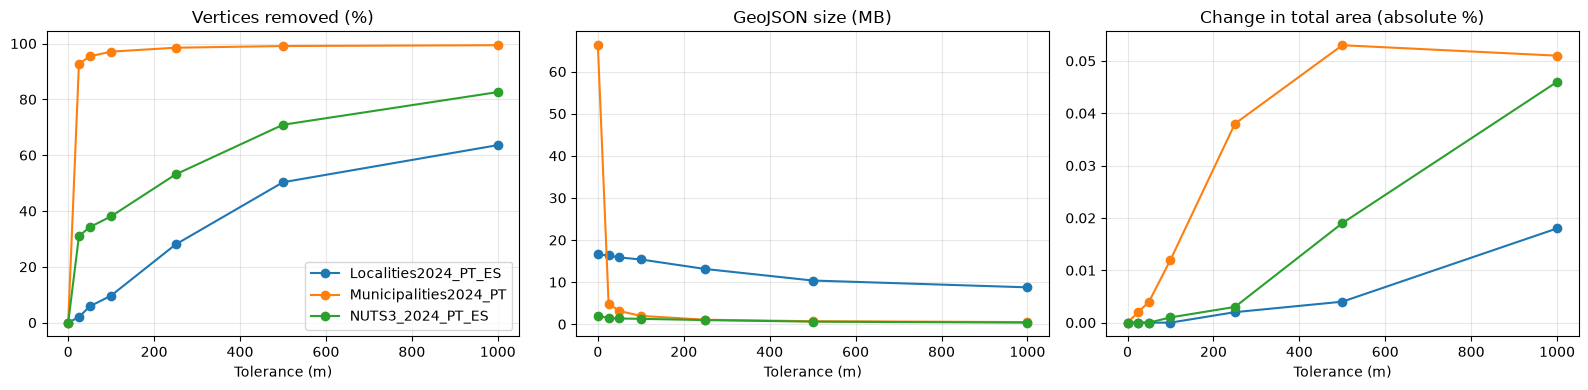

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for layer_name, group in df_results.groupby("layer"):
    axes[0].plot(group["tolerance_m"], group["vertex_reduction_%"], marker="o", label=layer_name)
    axes[1].plot(group["tolerance_m"], group["geojson_MB"], marker="o", label=layer_name)
    axes[2].plot(group["tolerance_m"], group["area_change_%"].abs(), marker="o", label=layer_name)

axes[0].set_title("Vertices removed (%)")
axes[1].set_title("GeoJSON size (MB)")
axes[2].set_title("Change in total area (absolute %)")
for ax in axes:
    ax.set_xlabel("Tolerance (m)")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()

### Visual comparison (municipalities around Lisbon)

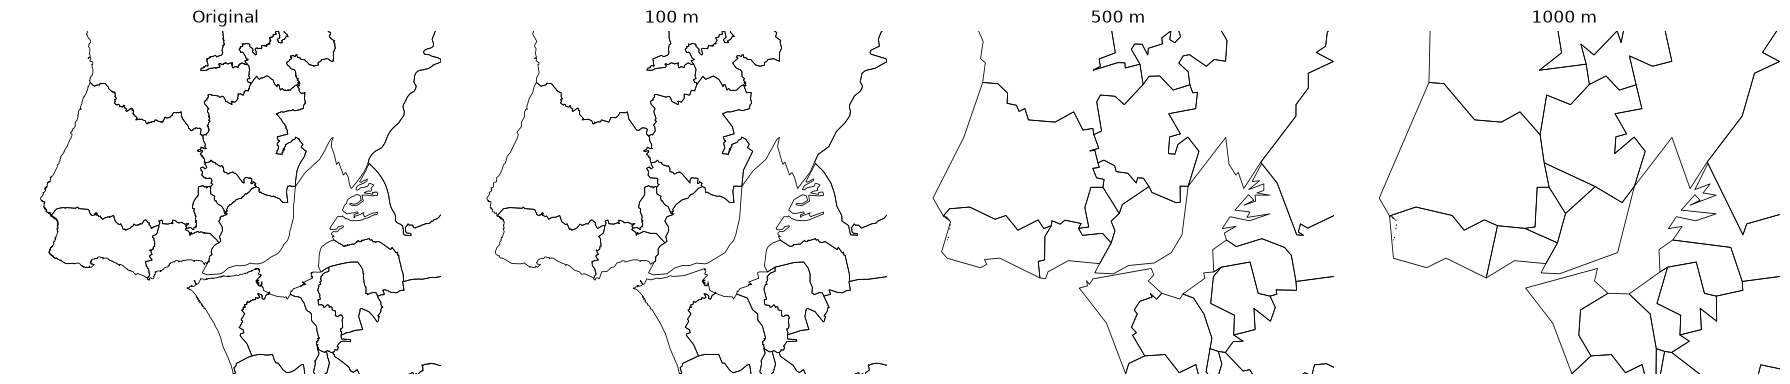

In [4]:
zoom_area = {"xlim": (-9.55, -8.85), "ylim": (38.55, 39.0)}
tolerances_to_show = [0, 100, 500, 1000]

fig, axes = plt.subplots(1, len(tolerances_to_show), figsize=(18, 5))
for ax, tolerance in zip(axes, tolerances_to_show):
    municipality_versions[tolerance].boundary.plot(ax=ax, linewidth=0.6, color="black")
    ax.set_xlim(*zoom_area["xlim"])
    ax.set_ylim(*zoom_area["ylim"])
    ax.set_title("Original" if tolerance == 0 else f"{tolerance} m")
    ax.set_axis_off()
plt.tight_layout()

### Why topology matters

The same municipalities simplified with 500 m, using a simple `simplify()` (each polygon on its own) and the topology method:

In [5]:
gdf_mun = load_layer("Municipalities2024_PT")

naive = gdf_mun.copy()
naive["geometry"] = gdf_mun.geometry.to_crs(PROJECTED_CRS).simplify(500).to_crs(OUTPUT_CRS)
topological = municipality_versions[500]

comparison = pd.DataFrame(
    [topology_errors_km2(gdf_mun), topology_errors_km2(naive), topology_errors_km2(topological)],
    columns=["overlaps_km2", "gaps_km2"],
    index=["original", "simple simplify()", "topology (topojson)"],
)
comparison

,overlaps_km2,gaps_km2
original,0.000,0.000
simple simplify(),364.018,360.771
topology (topojson),0.000,0.047


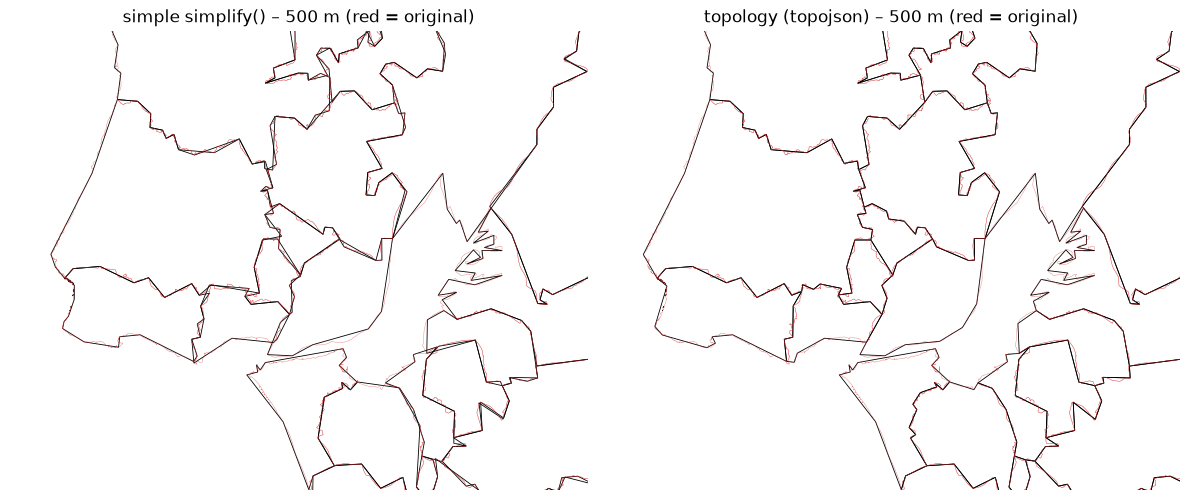

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, gdf) in zip(axes, [("simple simplify()", naive), ("topology (topojson)", topological)]):
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.6)
    gdf_mun.boundary.plot(ax=ax, color="tab:red", linewidth=0.3, alpha=0.6)
    ax.set_xlim(*zoom_area["xlim"])
    ax.set_ylim(*zoom_area["ylim"])
    ax.set_title(f"{title} – 500 m (red = original)")
    ax.set_axis_off()
plt.tight_layout()

### Choosing the tolerance

Criteria used:
1. **Change in area below 1 %** – the shapes stay faithful to the original.
2. **No new gaps or overlaps** compared with the original.
3. **The shapes still look right** at the zoom level used in the report.
4. Among the tolerances that meet 1–3, choose the one that **removes the most vertices**.

Larger units (countries, NUTS 1) are seen from far away, so they accept larger tolerances. Small units (localities) need smaller tolerances, otherwise they lose their shape.

The values below are a starting point. **Review them with the analysis table above** and adjust if needed.

## 2. Execution

In [7]:
# Tolerance (metres) for each type of layer
TOLERANCES_M = {
    "NUTS0": 1000,
    "NUTS1": 500,
    "NUTS2": 250,
    "NUTS3": 250,
    "Districts": 250,
    "Municipalities": 100,
    "Localities": 50,
}

### 2.1 Simplify the base layers

The topology is built only for the **base layers** – the most complete version of each type:

| Base layer | Used for |
|---|---|
| `NUTS0…3_2024_PT_ES` | NUTS with archipelagos (PT + ES, PT, ES) |
| `NUTS0…3_2024_PT_ES_mainland` | NUTS mainland (PT + ES, PT, ES) – their geometries were cut in notebook 04, so they need their own topology |
| `Localities2024_PT_ES` | All locality layers |
| `Districts2024_PT` | Districts (full and mainland) |
| `Municipalities2024_PT` | Municipalities (full and mainland) |

In [8]:
base_layers = {}
for level in [0, 1, 2, 3]:
    base_layers[f"NUTS{level}_2024_PT_ES"] = f"NUTS{level}"
    base_layers[f"NUTS{level}_2024_PT_ES_mainland"] = f"NUTS{level}"
base_layers["Localities2024_PT_ES"] = "Localities"
base_layers["Districts2024_PT"] = "Districts"
base_layers["Municipalities2024_PT"] = "Municipalities"

simplified_base = {}
summary = []

for layer_name, layer_type in base_layers.items():
    gdf = load_layer(layer_name)
    tolerance = TOLERANCES_M[layer_type]

    simplified = simplify_from_topology(build_topology(gdf), gdf, tolerance)
    simplified_base[layer_name] = simplified
    save_layer(simplified, f"{layer_name}_simplified")

    summary.append({
        "layer": layer_name,
        "tolerance_m": tolerance,
        "vertices_before": count_vertices(gdf),
        "vertices_after": count_vertices(simplified),
    })

Saved layer 'NUTS0_2024_PT_ES_simplified' (2 rows)
Saved layer 'NUTS0_2024_PT_ES_mainland_simplified' (2 rows)
Saved layer 'NUTS1_2024_PT_ES_simplified' (10 rows)
Saved layer 'NUTS1_2024_PT_ES_mainland_simplified' (7 rows)
Saved layer 'NUTS2_2024_PT_ES_simplified' (28 rows)
Saved layer 'NUTS2_2024_PT_ES_mainland_simplified' (22 rows)
Saved layer 'NUTS3_2024_PT_ES_simplified' (85 rows)
Saved layer 'NUTS3_2024_PT_ES_mainland_simplified' (71 rows)
Saved layer 'Localities2024_PT_ES_simplified' (11224 rows)
Saved layer 'Districts2024_PT_simplified' (29 rows)
Saved layer 'Municipalities2024_PT_simplified' (308 rows)


### 2.2 Create the simplified subsets

The other layers (Portugal only, Spain only, mainland) contain the same polygons as a base layer, just fewer rows. So, instead of simplifying them again, the rows are selected from the simplified base layer using the ID column.

This is faster and guarantees that **the same unit has exactly the same shape in every file**.

In [9]:
subsets = {}   # subset layer: (base layer, ID column)

for level in [1, 2, 3]:
    for country in ["PT", "ES"]:
        subsets[f"NUTS{level}_2024_{country}"] = (f"NUTS{level}_2024_PT_ES", f"NUTS{level}_ID")
        subsets[f"NUTS{level}_2024_{country}_mainland"] = (f"NUTS{level}_2024_PT_ES_mainland", f"NUTS{level}_ID")

for name in ["Localities2024_PT_ES_mainland", "Localities2024_PT", "Localities2024_PT_mainland",
             "Localities2024_ES", "Localities2024_ES_mainland"]:
    subsets[name] = ("Localities2024_PT_ES", "LocalityID")

subsets["Districts2024_PT_mainland"] = ("Districts2024_PT", "DistrictID")
subsets["Municipalities2024_PT_mainland"] = ("Municipalities2024_PT", "MunicipalityID")

for layer_name, (base_name, id_column) in subsets.items():
    gdf = load_layer(layer_name)
    base = simplified_base[base_name]
    simplified = base[base[id_column].isin(gdf[id_column])].copy()
    save_layer(simplified, f"{layer_name}_simplified")

    summary.append({
        "layer": layer_name,
        "tolerance_m": TOLERANCES_M[base_layers[base_name]],
        "vertices_before": count_vertices(gdf),
        "vertices_after": count_vertices(simplified),
    })

Saved layer 'NUTS1_2024_PT_simplified' (3 rows)
Saved layer 'NUTS1_2024_PT_mainland_simplified' (1 rows)
Saved layer 'NUTS1_2024_ES_simplified' (7 rows)
Saved layer 'NUTS1_2024_ES_mainland_simplified' (6 rows)
Saved layer 'NUTS2_2024_PT_simplified' (9 rows)
Saved layer 'NUTS2_2024_PT_mainland_simplified' (7 rows)
Saved layer 'NUTS2_2024_ES_simplified' (19 rows)
Saved layer 'NUTS2_2024_ES_mainland_simplified' (15 rows)
Saved layer 'NUTS3_2024_PT_simplified' (26 rows)
Saved layer 'NUTS3_2024_PT_mainland_simplified' (24 rows)
Saved layer 'NUTS3_2024_ES_simplified' (59 rows)
Saved layer 'NUTS3_2024_ES_mainland_simplified' (47 rows)
Saved layer 'Localities2024_PT_ES_mainland_simplified' (10857 rows)
Saved layer 'Localities2024_PT_simplified' (3092 rows)
Saved layer 'Localities2024_PT_mainland_simplified' (2882 rows)
Saved layer 'Localities2024_ES_simplified' (8132 rows)
Saved layer 'Localities2024_ES_mainland_simplified' (7975 rows)
Saved layer 'Districts2024_PT_mainland_simplified' (18 row

### 2.3 Results

In [10]:
df_summary = pd.DataFrame(summary)
df_summary["vertex_reduction_%"] = round(100 * (1 - df_summary["vertices_after"] / df_summary["vertices_before"]), 1)
df_summary

,layer,tolerance_m,vertices_before,vertices_after,vertex_reduction_%
0,NUTS0_2024_PT_ES,1000,11040,2153,80.5
1,NUTS0_2024_PT_ES_mainland,1000,7925,1464,81.5
2,NUTS1_2024_PT_ES,500,20881,6233,70.1
3,NUTS1_2024_PT_ES_mainland,500,17766,5207,70.7
4,NUTS2_2024_PT_ES,250,27759,13247,52.3
5,NUTS2_2024_PT_ES_mainland,250,24644,11608,52.9
6,NUTS3_2024_PT_ES,250,48893,22951,53.1
7,NUTS3_2024_PT_ES_mainland,250,45778,21306,53.5
8,Localities2024_PT_ES,50,295985,278893,5.8
9,Districts2024_PT,250,688757,10220,98.5


In [11]:
# Validation: every polygon layer has a simplified version with the same number of rows
all_layers = set(gpd.list_layers(LAYERS_GPKG)["name"])
for layer_name in sorted(all_layers):
    if layer_name.endswith("_simplified"):
        continue
    gdf = load_layer(layer_name)
    if not is_polygon_layer(gdf):
        continue
    simplified_name = f"{layer_name}_simplified"
    status = "OK" if simplified_name in all_layers and len(load_layer(simplified_name)) == len(gdf) else "CHECK"
    print(f"{status}  {layer_name}")

OK  Districts2024_PT
OK  Districts2024_PT_mainland
OK  Localities2024_ES
OK  Localities2024_ES_mainland
OK  Localities2024_PT
OK  Localities2024_PT_ES
OK  Localities2024_PT_ES_mainland
OK  Localities2024_PT_mainland
OK  Municipalities2024_PT
OK  Municipalities2024_PT_mainland
OK  NUTS0_2024_PT_ES
OK  NUTS0_2024_PT_ES_mainland
OK  NUTS1_2024_ES
OK  NUTS1_2024_ES_mainland
OK  NUTS1_2024_PT
OK  NUTS1_2024_PT_ES
OK  NUTS1_2024_PT_ES_mainland
OK  NUTS1_2024_PT_mainland
OK  NUTS2_2024_ES
OK  NUTS2_2024_ES_mainland
OK  NUTS2_2024_PT
OK  NUTS2_2024_PT_ES
OK  NUTS2_2024_PT_ES_mainland
OK  NUTS2_2024_PT_mainland
OK  NUTS3_2024_ES
OK  NUTS3_2024_ES_mainland
OK  NUTS3_2024_PT
OK  NUTS3_2024_PT_ES
OK  NUTS3_2024_PT_ES_mainland
OK  NUTS3_2024_PT_mainland


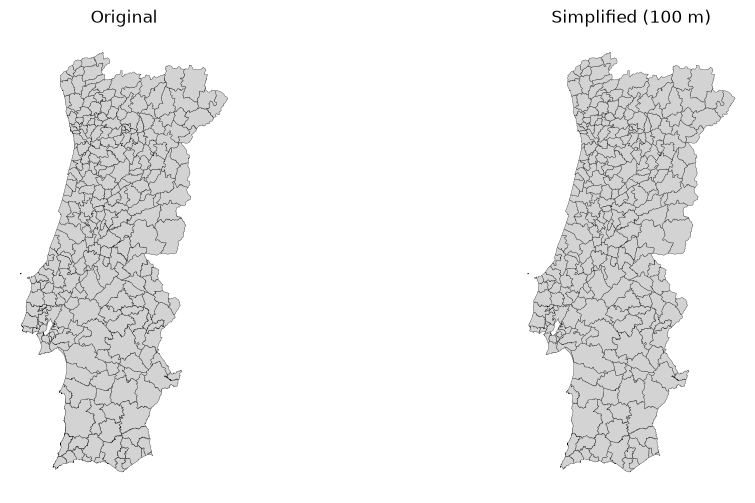

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
load_layer("Municipalities2024_PT_mainland").plot(ax=axes[0], edgecolor="black", linewidth=0.2, color="lightgrey")
load_layer("Municipalities2024_PT_mainland_simplified").plot(ax=axes[1], edgecolor="black", linewidth=0.2, color="lightgrey")
axes[0].set_title("Original")
axes[1].set_title(f"Simplified ({TOLERANCES_M['Municipalities']} m)")
for ax in axes:
    ax.set_axis_off()

## Summary
* **Analysis:** compared tolerances from 0 to 1000 m on three layers, measuring vertices, file size, change in area, gaps and overlaps, and comparing the shapes visually.
* Showed that a simple `simplify()` creates gaps and overlaps between neighbours, and that the topology method avoids them.
* **Execution:** simplified the base layers with one tolerance per layer type and created the simplified subsets by selecting rows from the base layers, so each unit has the same shape in every file.
* Saved all layers with the suffix `_simplified`. They are exported in notebook 07.